# Лабораторная работа №7. Построение автокодировщика

Власюк Данил Витальевич, Т26ИИКТ-МИК11. Вариант 3: набор «диск», архитектура conv → dense, d=8.

Цель: собрать и обучить автокодировщики, оценить реконструкцию на отложенной выборке, сравнить с тривиальным эталоном и отделить эффект архитектуры от разброса seed и ресурсной цены. Выполнение в отдельном ноутбуке Colab/T4 по приложенным PDF и Python-скриптам. Упоминание Engee в карточке задания расходится с требованиями приложений.

Задание 1: изучена [документация WorkspaceArray Engee](https://engee.com/helpcenter/stable/ru/guide/workspacearray.html). Этот AbstractArray представляет временные ряды с ленивой загрузкой. Поля time/value дают времена и значения, срез не копирует данные, collect загружает их в DataFrame. Для обучения ниже используются тензоры PyTorch.

Сцены синтетические, генерируются приложенным кодом; внешних фотографий и предобученных весов нет. Исходники преподавателя сохранены без изменения. Архивные результаты преподавателя не выдаются за свои.

# Гипотеза и допуски до обучения

Вариант 3, набор disc: один янтарный диск на градиентном фоне, факторы x, y, радиус. A=ConvAE(d=8), B=DenseAE(d=8). Меняется только семейство архитектуры, а число параметров является его следствием: это не сравнение моделей одинаковой ёмкости.

Гипотеза: полносвязная сеть с 256 скрытыми нейронами будет иметь существенно больше параметров. Свёрточная структура полезна для пространственных закономерностей, но преимущество по PSNR при данном объёме данных не гарантируется. Проверим направленное ожидание: выигрыш B относительно A не превысит 1 дБ и не оправдает увеличение ёмкости. Время может отличаться из-за разных операций; заранее не задаём его направление.

Общие условия: данные seed 7, 4096 обучающих и 1024 тестовых сцены, 32×32 RGB; обучение seed 101–105; Adam, lr=0.002, batch=128, 20 эпох (640 обновлений), MSE, чистые входы, dtype=float32, одна T4.

Допуски: тестовый PSNR ±1 дБ; разрыв train−test ±0.1 дБ; время ±20% среднего A; для числа параметров дополнительный ресурсный допуск ±20% A. Для PSNR рост выше допуска — улучшение. Для времени и числа параметров снижение выше допуска — экономия (улучшение); для разрыва рост — ухудшение обобщения, а снижение — улучшение лишь в смысле этого показателя, не доказательство качества. В пределах допуска — нейтрально.

Отдельно рассчитываем |Δ|>2s_A по методичке: учебная эвристика, не p-value. При s=0 и ненулевом Δ отношение бесконечно; у числа параметров это детерминированное различие, а не статистическое доказательство. Эталон — среднее только по train, оценённое на test. PSNR усредняется по изображениям, а не вычисляется из общего среднего MSE.

Ошибка интерпретации: нельзя объявлять PSNR «хорошим» без эталона или малое d достаточным без диагностики. Проверим ConvAE d=1,2,3,4,8 на seed 101–103. Непрерывных факторов три, но пиксельный рендер дискретен; из одного числа факторов нельзя выводить строгое универсальное минимальное d. Нужны измерения, архитектура и оговорки.

Записано: 2026-10-29T10:58:47.332777+03:00

## 1. Среда и исходники

Выбрать T4 GPU и Run all. Обучение на CPU намеренно не запускается. SHA-256 обеих библиотек из архива совпадают; используется lab07_lib.py. Версии и настройки фиксируются фактически.

In [1]:
import sys,subprocess,datetime,time,pathlib,json,hashlib,shutil,platform
import numpy as np,torch
from PIL import Image
from IPython.display import display,Markdown
STARTED=datetime.datetime.now(datetime.timezone.utc).isoformat()
assert torch.cuda.is_available(),'Выберите GPU T4'
GPU=subprocess.check_output(['nvidia-smi','--query-gpu=name,memory.total,driver_version','--format=csv'],text=True)
print(STARTED,sys.version,torch.__version__,GPU)
OUT=pathlib.Path('/content/LR07_variant3_results');OUT.mkdir(exist_ok=True)
def write_json(p,x):p.write_text(json.dumps(x,ensure_ascii=False,indent=2,default=lambda x:x.item())+'\n')

2026-10-29T08:03:45.551427+00:00 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0] 2.11.0+cu130 name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07



In [2]:
%%writefile lab07_lib.py
# ЛР 7. Построение автокодировщика. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128. Внешние данные не нужны: сцены порождаются кодом.
import time
import numpy as np
import torch
import torch.nn as nn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N = 32                      # сторона изображения
SEEDS = range(101, 106)     # серия seed обучения
KINDS = ["disc", "disc_rect", "disc_noise", "disc_color", "two_discs"]   # пять контекстов (наборов данных)
N_FACTORS = {"disc": 3, "disc_rect": 4, "disc_noise": 3, "disc_color": 4, "two_discs": 4}
AMBER, GREEN, PINK = (1.0, 0.76, 0.29), (0.24, 0.86, 0.60), (0.95, 0.35, 0.55)
_YY, _XX = np.mgrid[0:N, 0:N] / (N - 1)


def _disc(img, cx, cy, r, color):
    m = (_XX - cx) ** 2 + (_YY - cy) ** 2 <= r * r
    for k in range(3):
        img[k][m] = color[k]


def _hue(h):
    """Простой цвет по параметру 0..1 (три сдвинутые косинусоиды)."""
    return tuple(0.5 + 0.5 * np.cos(2 * np.pi * (h + s)) for s in (0.0, 1 / 3, 2 / 3))


def render(kind, f):
    """Сцена 3×N×N по вектору факторов f из отрезка [0, 1]: положения и размеры объектов задают изображение однозначно."""
    img = np.zeros((3, N, N), dtype=np.float32)
    img[:] = (0.10 + 0.25 * (_XX + _YY) / 2)[None]
    if kind in ("disc", "disc_noise"):
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], AMBER)
    elif kind == "disc_rect":
        _disc(img, 0.25 + 0.5 * f[0], 0.30 + 0.25 * f[1], 0.12 + 0.08 * f[2], AMBER)
        x0 = int((0.05 + 0.55 * f[3]) * N); img[:, int(0.72 * N):int(0.92 * N), x0:x0 + int(0.3 * N)] = np.array(GREEN)[:, None, None]
    elif kind == "disc_color":
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], _hue(f[3]))
    elif kind == "two_discs":
        _disc(img, 0.15 + 0.3 * f[0], 0.15 + 0.7 * f[1], 0.12, AMBER)
        _disc(img, 0.55 + 0.3 * f[2], 0.15 + 0.7 * f[3], 0.12, PINK)
    else:
        raise ValueError(kind)
    return img


_CACHE = {}


def dataset(kind, n_train=4096, n_test=1024):
    """Обучающая и тестовая выборки (тензоры на устройстве) и факторы. Данные одинаковы для всех запусков (seed 7)."""
    if kind not in _CACHE:
        rng = np.random.default_rng(7)
        f = rng.random((n_train + n_test, N_FACTORS[kind]))
        x = np.stack([render(kind, fi) for fi in f])
        if kind == "disc_noise":
            x = np.clip(x + 0.05 * rng.standard_normal(x.shape).astype(np.float32), 0, 1)
        X = torch.tensor(x, dtype=torch.float32, device=DEVICE); F = torch.tensor(f, dtype=torch.float32, device=DEVICE)
        _CACHE[kind] = (X[:n_train], X[n_train:], F[:n_train], F[n_train:])
    return _CACHE[kind]


class ConvAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, 16, 4, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(),
                                 nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Flatten(), nn.Linear(64 * 16, d))
        self.dec_fc = nn.Sequential(nn.Linear(d, 64 * 16), nn.ReLU())
        self.dec = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(16, 3, 4, 2, 1), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(self.dec_fc(z).view(-1, 64, 4, 4))

    def forward(self, x):
        return self.decode(self.encode(x))


class DenseAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(3 * N * N, 256), nn.ReLU(), nn.Linear(256, d))
        self.dec = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 3 * N * N), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z).view(-1, 3, N, N)

    def forward(self, x):
        return self.decode(self.encode(x))


def build(arch, d):
    return (ConvAE if arch == "conv" else DenseAE)(d).to(DEVICE)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def psnr_images(x, y):
    """Средний по изображениям PSNR, дБ (значения 0..1)."""
    mse = ((x - y) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return float((10 * torch.log10(1.0 / mse)).mean())


def train(model, Xtr, epochs=20, lr=2e-3, loss="mse", noise=0.0, seed=0, batch=128):
    """Обучение с Adam. loss: 'mse' или 'l1'. noise > 0: вход зашумляется (шумоподавляющий автокодировщик), цель — чистое изображение."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = Xtr.shape[0]
    for _ in range(epochs):
        perm = torch.randperm(n, generator=g).to(DEVICE)
        for i in range(0, n, batch):
            x = Xtr[perm[i:i + batch]]
            xin = (x + noise * torch.randn(x.shape, generator=g).to(DEVICE)).clamp(0, 1) if noise > 0 else x
            out = model(xin)
            l = ((out - x) ** 2).mean() if loss == "mse" else (out - x).abs().mean()
            opt.zero_grad(); l.backward(); opt.step()
    return model


@torch.no_grad()
def reconstruct(model, X, eval_noise=0.0, seed=1234):
    model.eval()
    if eval_noise > 0:
        g = torch.Generator(device="cpu").manual_seed(seed)
        X = (X + eval_noise * torch.randn(X.shape, generator=g).to(DEVICE)).clamp(0, 1)
    return model(X)


# Шесть факторов: изменение базового режима A (свёрточный автокодировщик, d = 8, MSE, чистые данные, 4096 примеров).
FACTORS = ["latent_8_to_2", "latent_8_to_32", "arch_conv_to_dense", "loss_mse_to_l1", "input_clean_to_denoising", "train_4096_to_512"]
BASE = dict(arch="conv", d=8, loss="mse", noise=0.0, eval_noise=0.0, n_train=4096, epochs=20)


def settings(factor):
    a, b = dict(BASE), dict(BASE)
    if factor == "latent_8_to_2":
        b["d"] = 2
    elif factor == "latent_8_to_32":
        b["d"] = 32
    elif factor == "arch_conv_to_dense":
        b["arch"] = "dense"
    elif factor == "loss_mse_to_l1":
        b["loss"] = "l1"
    elif factor == "input_clean_to_denoising":
        a["eval_noise"] = b["eval_noise"] = 0.2; b["noise"] = 0.2
    elif factor == "train_4096_to_512":
        b["n_train"] = 512; b["epochs"] = 160   # 512 / 128 * 160 = 640 шагов, как 4096 / 128 * 20: число обновлений весов сохранено
    else:
        raise ValueError(factor)
    return a, b


def run(kind, cfg, seed):
    """Одно обучение: метрики на тестовой выборке."""
    Xtr, Xte, _, _ = dataset(kind)
    Xtr = Xtr[:cfg["n_train"]]
    torch.manual_seed(seed)
    t0 = time.perf_counter()
    model = train(build(cfg["arch"], cfg["d"]), Xtr, cfg["epochs"], loss=cfg["loss"], noise=cfg["noise"], seed=seed)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    p_te = psnr_images(reconstruct(model, Xte, cfg["eval_noise"]), Xte)
    p_tr = psnr_images(reconstruct(model, Xtr[:1024], cfg["eval_noise"]), Xtr[:1024])
    return dict(psnr=p_te, gap=p_tr - p_te, params=n_params(model) / 1000, seconds=dt), model


def variant_summary(n, seeds=SEEDS):
    """Вариант n = 1..30: набор данных c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k])
    A = {m: [] for m in ("psnr", "gap", "params", "seconds")}
    B = {m: [] for m in A}
    run(KINDS[c], a_cfg, 0)  # прогрев
    for s in seeds:
        ma, _ = run(KINDS[c], a_cfg, s)
        mb, _ = run(KINDS[c], b_cfg, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)

Writing lab07_lib.py


In [3]:
%%writefile lab07_demo.py
# ЛР 7. Демонстрационный вариант 1: набор «диск», фактор «размер латентного вектора 8 → 2».
import numpy as np
import lab07_lib as L

N = 1
c, k = (N - 1) // 6, (N - 1) % 6
a_cfg, b_cfg = L.settings(L.FACTORS[k])
print("A:", a_cfg)
print("B:", b_cfg)

# Серия из пяти seed: метрики режимов A и B
result = L.variant_summary(N)
for name, a, s, b, d, q, sig in result["rows"]:
    print(f"{name:8s} A={a:8.3f} s={s:6.3f} B={b:8.3f} d={d:+8.3f} |d|/s={q:7.2f} 2s={'да' if sig else 'нет'}")

# Тривиальный эталон: средняя картинка обучающей выборки, одинаковая для всех входов
Xtr, Xte, Ftr, Fte = L.dataset(L.KINDS[c])
mean_image = Xtr.mean(0, keepdim=True).expand_as(Xte)
print("эталон «средняя картинка», PSNR на тесте:", round(L.psnr_images(mean_image, Xte), 3))

# Диагностика: PSNR в зависимости от размера латентного вектора (seed 101, 102, 103)
for d in (1, 2, 3, 4, 8):
    vals = [L.run(L.KINDS[c], dict(L.BASE, d=d), s)[0]["psnr"] for s in (101, 102, 103)]
    print(f"d={d}: PSNR = {np.mean(vals):.2f} дБ (по seed: {', '.join(f'{v:.2f}' for v in vals)})")

# Лист сравнения comparison.png: оригиналы, реконструкции режима A и режима B (seed 101, первые 8 тестовых сцен)
from PIL import Image
rows = [Xte[:8]]
for cfg in (a_cfg, b_cfg):
    model = L.run(L.KINDS[c], cfg, 101)[1]
    rows.append(L.reconstruct(model, Xte[:8], cfg["eval_noise"]))
grid = np.concatenate([np.concatenate(list(r.permute(0, 2, 3, 1).cpu().numpy()), axis=1) for r in rows], axis=0)
sheet = Image.fromarray((grid * 255).round().astype("uint8")).resize((8 * 32 * 4, 3 * 32 * 4), Image.NEAREST)
sheet.save("comparison.png")
sheet

Writing lab07_demo.py


In [4]:
EXPECTED={'lab07_lib.py': 'd84b83a878f55e95289d76a788dc9fa84d3249d0d33aa719d9db8d6792fd2698', 'lab07_demo.py': 'fce7924908adbef63dd5808a800a3c9f5b96c137dc9ebf9d398fc2eb613d95fa'}
for name,sha in EXPECTED.items():
 assert hashlib.sha256(pathlib.Path(name).read_bytes()).hexdigest()==sha,name
 shutil.copy2(name,OUT/name);print(name,sha)
import lab07_lib as L
assert L.DEVICE=='cuda'

lab07_lib.py d84b83a878f55e95289d76a788dc9fa84d3249d0d33aa719d9db8d6792fd2698
lab07_demo.py fce7924908adbef63dd5808a800a3c9f5b96c137dc9ebf9d398fc2eb613d95fa


## 2. Предоставленное демо целиком

lab07_demo.py выполняется без изменения. Обёртка L.run фиксирует возвращённые метрики после каждого обучения; код обучения и измерения времени не меняется. Демо использует тот же набор disc, поэтому его диагностика d=1,2,3,4,8 на seed 101–103 применима к нашему набору без повторного обучения. Диагностика относится к ConvAE; переносить её автоматически на DenseAE нельзя.

A: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
B: {'arch': 'conv', 'd': 2, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
psnr     A=  25.943 s= 0.716 B=  23.208 d=  -2.735 |d|/s=   3.82 2s=да
gap      A=   0.040 s= 0.013 B=   0.102 d=  +0.063 |d|/s=   4.79 2s=да
params   A= 101.035 s= 0.000 B=  88.741 d= -12.294 |d|/s=    inf 2s=да
seconds  A=   1.803 s= 0.082 B=   1.762 d=  -0.041 |d|/s=   0.51 2s=нет
эталон «средняя картинка», PSNR на тесте: 17.171
d=1: PSNR = 20.67 дБ (по seed: 20.64, 20.77, 20.60)
d=2: PSNR = 23.16 дБ (по seed: 23.30, 23.45, 22.72)
d=3: PSNR = 25.28 дБ (по seed: 24.84, 24.84, 26.16)
d=4: PSNR = 26.52 дБ (по seed: 27.11, 26.33, 26.11)
d=8: PSNR = 25.83 дБ (по seed: 25.76, 26.69, 25.04)


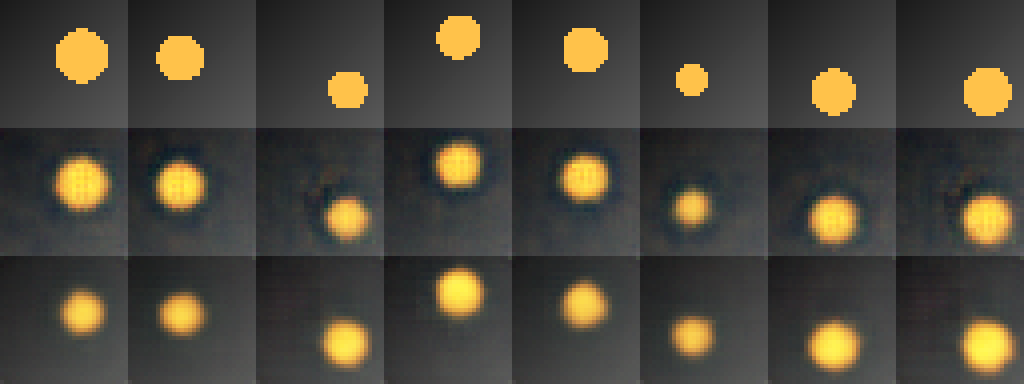

In [5]:
original_run=L.run;demo_records=[]
def demo_recorded_run(kind,cfg,seed):
    metrics,model=original_run(kind,cfg,seed)
    demo_records.append(dict(kind=kind,settings=dict(cfg),seed=seed,metrics=metrics))
    return metrics,model
L.run=demo_recorded_run
try:
    exec(compile(pathlib.Path('lab07_demo.py').read_text(),'lab07_demo.py','exec'),globals())
finally:L.run=original_run
assert len(demo_records)==28
write_json(OUT/'demo_records.json',demo_records)
write_json(OUT/'demo_summary.json',result)
shutil.copy2('comparison.png',OUT/'comparison_demo_variant01.png')
display(sheet)
diagnostic=demo_records[11:26]
assert [r['settings']['d'] for r in diagnostic]==[d for d in [1,2,3,4,8] for _ in range(3)]
write_json(OUT/'diagnostic.json',diagnostic)

## 3. Данные, архитектуры и эталон

ConvAE: три свёртки с шагом 2 (32→16→8→4), линейное сжатие в 8 чисел; декодер выполняет обратное развёртывание и ConvTranspose2d, Sigmoid ограничивает RGB в 0…1. DenseAE: Flatten 3072→256→8→256→3072, ReLU и Sigmoid. Пространственные связи у DenseAE не встроены, количество весов меняется вместе с архитектурой. Обе модели обучаются MSE и оцениваются средним PSNR по 1024 test-сценам. Эталон вычисляется только из train.

In [6]:
N=3;c,k=(N-1)//6,(N-1)%6
kind=L.KINDS[c];a_cfg,b_cfg=L.settings(L.FACTORS[k])
assert [key for key in a_cfg if a_cfg[key]!=b_cfg[key]]==['arch']
Xtr,Xte,Ftr,Fte=L.dataset(kind)
assert Xtr.shape==(4096,3,32,32) and Xte.shape==(1024,3,32,32)
np.savez_compressed(OUT/'dataset.npz',train=Xtr.cpu().numpy(),test=Xte.cpu().numpy(),factors_train=Ftr.cpu().numpy(),factors_test=Fte.cpu().numpy())
mean_train=Xtr.mean(0,keepdim=True)
baseline=L.psnr_images(mean_train.expand_as(Xte),Xte)
np.save(OUT/'mean_train.npy',mean_train.cpu().numpy())
write_json(OUT/'baseline.json',dict(psnr=baseline,method='mean over training images only, average per-image test PSNR',train=4096,test=1024,data_seed=7,scene_factors=3))
print('A',a_cfg,'B',b_cfg,'baseline',baseline)

A {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20} B {'arch': 'dense', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20} baseline 17.170730590820312


## 4. Основная серия варианта 3

Вызывается неизменённая L.variant_summary(3), включая прогрев. Обёртка сохраняет метрики и поизображенные MSE train/test для всех пяти seed; для seed 101 дополнительно сохраняются веса обеих моделей и первые восемь реконструкций float32. Это позволяет проверить таблицу и сравнительный лист. Модели на листе взяты из основной серии, не из нового обучения.

In [7]:
records=[];models_101={}
def recorded_run(kind,cfg,seed):
    metrics,model=original_run(kind,cfg,seed)
    if seed in range(101,106):
        condition='A' if cfg==a_cfg else 'B'
        with torch.no_grad():
            pte=L.reconstruct(model,Xte,cfg['eval_noise']);ptr=L.reconstruct(model,Xtr[:1024],cfg['eval_noise'])
            mse_test=((pte-Xte)**2).flatten(1).mean(1).cpu().numpy()
            mse_train=((ptr-Xtr[:1024])**2).flatten(1).mean(1).cpu().numpy()
        name=f'{condition}_{seed}_errors.npz'
        np.savez_compressed(OUT/name,mse_test=mse_test,mse_train=mse_train)
        rec=dict(condition=condition,kind=kind,settings=dict(cfg),seed=seed,metrics=metrics,errors=name)
        records.append(rec)
        if seed==101:
            torch.save(model.state_dict(),OUT/f'{condition}_101_weights.pt')
            np.save(OUT/f'{condition}_101_predictions.npy',pte[:8].cpu().numpy())
            models_101[condition]=model
        print('DONE',condition,seed,metrics)
    return metrics,model
L.run=recorded_run
try:result=L.variant_summary(N)
finally:L.run=original_run
assert len(records)==10
write_json(OUT/'records.json',records);write_json(OUT/'summary.json',result)
for row in result['rows']:print(row)

DONE A 101 {'psnr': 25.839370727539062, 'gap': 0.03539466857910156, 'params': 101.035, 'seconds': 1.7043153550000625}
DONE B 101 {'psnr': 25.803054809570312, 'gap': 0.11465072631835938, 'params': 1580.552, 'seconds': 1.1063863929999798}
DONE A 102 {'psnr': 26.59311866760254, 'gap': 0.051059722900390625, 'params': 101.035, 'seconds': 1.7102636040000334}
DONE B 102 {'psnr': 25.728260040283203, 'gap': 0.1213531494140625, 'params': 1580.552, 'seconds': 1.106402772000024}
DONE A 103 {'psnr': 25.048969268798828, 'gap': 0.034389495849609375, 'params': 101.035, 'seconds': 1.6869562819999828}
DONE B 103 {'psnr': 25.566911697387695, 'gap': 0.11866378784179688, 'params': 1580.552, 'seconds': 1.1291043469999522}
DONE A 104 {'psnr': 26.468135833740234, 'gap': 0.05181694030761719, 'params': 101.035, 'seconds': 1.7708798219999835}
DONE B 104 {'psnr': 25.613994598388672, 'gap': 0.11828994750976562, 'params': 1580.552, 'seconds': 1.114519157000018}
DONE A 105 {'psnr': 26.47624969482422, 'gap': 0.041717

## 5. Таблица, допуски, эталон и диагностика

PSNR выше — точнее, время и число параметров ниже — экономнее; малый gap означает меньший разрыв, но не сам по себе хорошую реконструкцию. Число параметров детерминировано, при s=0 статистический смысл 2s отсутствует. В базовой библиотеке отношение записывается Infinity. Практическую ресурсную классификацию параметров приводим отдельно от качества.

In [8]:
TOLS={'psnr':1.,'gap':.1,'params':.2,'seconds':.2}
classified=[]
for metric,a,s,b,d,ratio,sig in result['rows']:
    tolerance=TOLS[metric] if metric in ['psnr','gap'] else TOLS[metric]*abs(a)
    practical=bool(abs(d)>tolerance)
    direction=d if metric=='psnr' else -d
    label='нейтрально' if not practical else 'улучшение' if direction>0 else 'ухудшение'
    classified.append(dict(metric=metric,A=a,s_A=s,B=b,delta=d,ratio=ratio,over_2s=sig,tolerance=tolerance,practical=practical,label=label,criteria_disagree=bool(sig)!=practical,deterministic=metric=='params'))
write_json(OUT/'classification.json',classified)
def table(rows):
    header='| Метрика | A | s_A | B | Δ | abs(Δ)/s | >2s | Допуск | Класс |\n|---|---:|---:|---:|---:|---:|---|---:|---|\n'
    return header+'\n'.join(f"| {r['metric']} | {r['A']:.6f} | {r['s_A']:.6f} | {r['B']:.6f} | {r['delta']:+.6f} | {r['ratio']:.3f} | {r['over_2s']} | {r['tolerance']:.6f} | {r['label']} |" for r in rows)
display(Markdown(table(classified)))
print('Baseline',baseline)
for r in classified:
    if r['metric']=='psnr':print('Gain above baseline: A',r['A']-baseline,'B',r['B']-baseline)
print('Disagreement',[r['metric'] for r in classified if r['criteria_disagree']])
diag_summary=[]
for d in [1,2,3,4,8]:
    values=[r['metrics']['psnr'] for r in diagnostic if r['settings']['d']==d]
    diag_summary.append(dict(d=d,mean=float(np.mean(values)),s=float(np.std(values,ddof=1)),values=values))
write_json(OUT/'diagnostic_summary.json',diag_summary)
print('Diagnostic',json.dumps(diag_summary,indent=2))

| Метрика | A | s_A | B | Δ | abs(Δ)/s | >2s | Допуск | Класс |
|---|---:|---:|---:|---:|---:|---|---:|---|
| psnr | 26.085169 | 0.650336 | 25.693578 | -0.391591 | 0.602 | False | 1.000000 | нейтрально |
| gap | 0.042876 | 0.008310 | 0.118402 | +0.075526 | 9.088 | True | 0.100000 | нейтрально |
| params | 101.035000 | 0.000000 | 1580.552000 | +1479.517000 | inf | True | 20.207000 | ухудшение |
| seconds | 1.718323 | 0.031654 | 1.114104 | -0.604219 | 19.088 | True | 0.343665 | улучшение |

Baseline 17.170730590820312
Gain above baseline: A 8.914438247680664 B 8.522847366333007
Disagreement ['gap']
Diagnostic [
  {
    "d": 1,
    "mean": 20.670546849568684,
    "s": 0.09001555293734691,
    "values": [
      20.63599967956543,
      20.77271842956543,
      20.602922439575195
    ]
  },
  {
    "d": 2,
    "mean": 23.15778160095215,
    "s": 0.3852950463907936,
    "values": [
      23.29865837097168,
      23.45281219482422,
      22.721874237060547
    ]
  },
  {
    "d": 3,
    "mean": 25.27944501241048,
    "s": 0.7626060596211345,
    "values": [
      24.838809967041016,
      24.83949851989746,
      26.16002655029297
    ]
  },
  {
    "d": 4,
    "mean": 26.515340169270832,
    "s": 0.5262315178938447,
    "values": [
      27.108631134033203,
      26.332378387451172,
      26.105010986328125
    ]
  },
  {
    "d": 8,
    "mean": 25.82958221435547,
    "s": 0.8243340888459766,
    "values": [
      25.755767822265625,
      26.68834114074707,
      25.04463768

## 6. Сравнительный лист

Первые восемь test-сцен, seed обучения 101. Строки сверху вниз: оригиналы; ConvAE d=8; DenseAE d=8. Пиксели увеличены методом NEAREST без сглаживания, исходный размер 32×32. Численная оценка PSNR выполнена по float32 до округления в PNG.

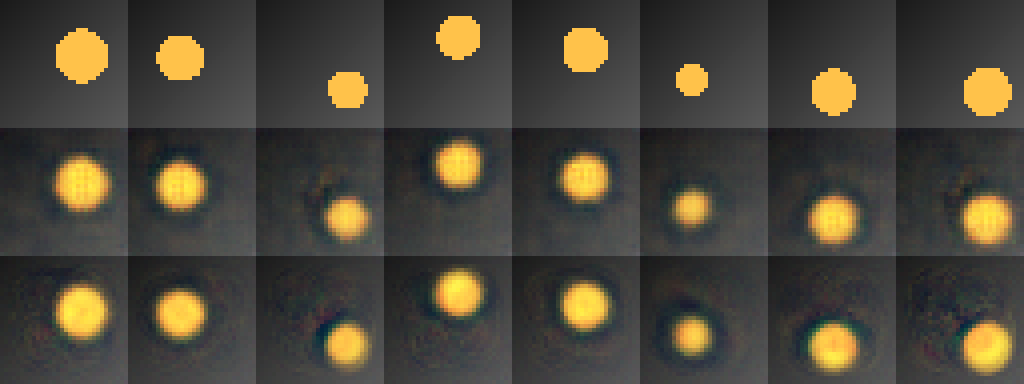

In [9]:
rows=[Xte[:8].cpu().numpy(),np.load(OUT/'A_101_predictions.npy'),np.load(OUT/'B_101_predictions.npy')]
grid=np.concatenate([np.concatenate(list(r.transpose(0,2,3,1)),axis=1) for r in rows],axis=0)
sheet=Image.fromarray((grid*255).round().astype('uint8')).resize((1024,384),Image.Resampling.NEAREST)
sheet.save(OUT/'comparison.png');display(sheet)

## 7. Анализ и контрольные вопросы

# Итоговый вывод

Гипотеза о том, что большой рост ёмкости DenseAE не даст выигрыша более 1 дБ, в проверенных условиях согласуется с наблюдением: A=26,0852 дБ, B=25,6936 дБ, Δ=−0,3916 дБ; |Δ|/s_A=0,602. По допуску ±1 дБ и критерию 2s отклик нейтрален. A лучше эталона на 8,9144 дБ, B на 8,5228 дБ; обе сети извлекают информацию о сцене, а не просто рисуют средний фон.

Разрыв train−test вырос с 0,0429 до 0,1184 дБ, Δ=+0,0755 дБ. Критерий 2s выполнен (отношение 9,09), но практический допуск ±0,1 дБ не превышен: класс нейтральный. Это пример расхождения критериев, а не противоречие. Малый разброс A позволяет эвристике 2s выделить практически небольшое изменение. Речь не идёт о формальном статистическом тесте.

Число параметров выросло со 101 035 до 1 580 552 (в 15,64 раза, +1464,36%). По заранее заданному ресурсному допуску 20% это ухудшение. Время обучения, напротив, снизилось с 1,7183 до 1,1141 с (−35,16%): улучшение по 20% допуску и эффект больше 2s. Больше весов не обязательно означает большее время на GPU: полносвязные и свёрточные операции используют разные вычислительные пути.

Выбор зависит от ограничения: ConvAE даёт сопоставимое качество при гораздо меньшем числе весов; DenseAE быстрее обучалась в этой среде, но не улучшила реконструкцию. Причину нельзя свести только к пространственной структуре, потому что сравнение не выравнивает число параметров и не исследует сходимость при других бюджетах. На сравнительном листе обе модели размывают границы и лишь приближённо сохраняют круг, размер и положение.

Диагностика d=1,2,3,4,8 показывает потерю качества при слишком узком коде и отсутствие строгой монотонности. Выводы ограничены одним синтетическим набором, двумя архитектурами, пятью seed, 20 эпохами и данным GPU. На фотографии и иные модели результат не переносится без проверки. Новая сессия и локальное повторное обучение отдельно не выполнялись; сохранённые результаты проверяются независимо по данным, ошибкам и формулам.


# Визуальный анализ seed 101

На оригиналах диск имеет резкую пиксельную границу, меняет положение и радиус. В строках A и B положение основных ярких пятен в целом соответствует исходным сценам; различие больших и малых дисков сохранено. Грубого переноса диска в другой участок кадра в этих восьми примерах не видно. Это визуальная оценка, а не измерение нулевого смещения центров.

Обе модели восстанавливают диск как мягкое округлое пятно: границы размыты, вокруг объектов заметны ореолы и неоднородности цвета. В A видны повторяющиеся мелкие структуры вокруг границы; B также сглаживает границу и создаёт цветовой ореол. Радиусы и форма приближённые, а не точные: требование «круглый диск, размер и положение без смещения» выполнено лишь приближённо.

По этому листу нет основания объявлять одну модель визуально однозначно лучше: обе теряют чёткость, а разница среднего PSNR основной серии меньше практического допуска. Лист показывает первые восемь test-сцен и один seed; основная оценка использует всю тестовую выборку и пять seed.


# Анализ диагностики

Для ConvAE на наборе disc средний PSNR вырос с 20,67 дБ при d=1 до 23,16 при d=2, 25,28 при d=3 и 26,52 при d=4; при d=8 получили 25,83 дБ. Значение при d=2 на 5,99 дБ выше эталона 17,17, но этого недостаточно, чтобы объявить два числа достаточными: d=4 лучше d=2 на 3,36 дБ. Наблюдение согласуется с потерей части информации при слишком узком коде.

Рост не строго монотонный: d=8 хуже d=4 на 0,69 дБ, что меньше практического допуска 1 дБ. По трём seed нельзя объявлять d=4 универсально оптимальным. На результат влияют оптимизация, архитектура и конечная выборка. Набор имеет три непрерывных порождающих фактора, но из этого не следует строгая теорема о минимальном d для дискретного рендера или любого способа кодирования.

Диагностика выполнена в составе полного собственного демо. Вариант 3 использует тот же disc, поэтому это выполнение обязательной диагностики на своём наборе. Она не подменяет основную серию сравнения ConvAE/DenseAE с d=8.


# Ответы на контрольные вопросы

1. Автокодировщик получает изображение и восстанавливает его же; цель - близость реконструкции к исходнику (MSE, PSNR). Классификатор предсказывает класс, обучается по меткам и оценивается, например, точностью. Здесь метки классов не нужны.

2. Узкое место ограничивает представление и заставляет сохранять полезные свойства. При d не меньше размерности входа сжатие не гарантируется: сеть может выучить почти тождественную функцию. Это не запрещает полезное обучение при других ограничениях, но одна архитектура уже не вынуждает к компактному коду.

3. Test не участвует в обновлении весов и показывает обобщение на новые сцены. Положительный разрыв PSNR_train−PSNR_test может указывать на переобучение, однако малый разрыв бывает и при недообучении. Нужны оба абсолютных PSNR и эталон.

4. Средняя картинка - среднее только по train, одинаковое для всех test-входов. Фон уже позволяет получить заметный PSNR без распознавания сцены. Поэтому приводятся PSNR эталона и выигрыш каждой модели; сам по себе порог «выше 20 дБ» недостаточен.

5. У disc три порождающих фактора: координаты x/y и радиус. Это ориентир для ёмкости кода; диагностика d=1,2,3,4,8 проверяет потерю информации. Строгий минимальный d не следует лишь из счёта факторов: рендер дискретен, выборка конечна, а результат зависит от архитектуры и оптимизации.

6. Цель шумоподавляющего AE - чистая сцена: шум во входе нужно отбросить. При сравнении с зашумлённой целью сеть поощряется воспроизводить шум. В нашем основном варианте оба режима обучаются на чистых входах; фактор шума не меняется.

7. Выигрыш 25,8−19,0=6,8 дБ. Для одного и того же способа агрегации PSNR это соответствует примерно 10^(6,8/10)=4,79 раза по отношению геометрических средних MSE, а не обязательно отношению арифметических средних ошибок.

8. L1 и MSE штрафуют ошибки по-разному: MSE сильнее реагирует на большие отклонения, а PSNR прямо связан с MSE. Поэтому близкий внешний вид не гарантирует одинаковый PSNR. При сравнении нужен одинаковый бюджет обучения и проверка сходимости.

9. При меньшем объёме train особенности отдельных примеров и случайная инициализация сильнее влияют на найденные веса; риск переобучения и вариативность могут расти. Это проверяется серией seed, а не считается обязательным для любой задачи.

10. Нужны генератор и seed данных, размеры train/test, код сцены и разделение выборок; архитектуры и d; seed обучения 101–105; Adam, lr, batch, эпохи и loss; настройки шума; GPU/драйвер, Python, PyTorch и dtype; определение PSNR, gap, ddof=1 и допуски. Побитовое совпадение GPU-обучения и времени не обещается.


Источники: приложенные PDF и неизменённые lab07_lib.py / lab07_demo.py; [документация WorkspaceArray](https://engee.com/helpcenter/stable/ru/guide/workspacearray.html). Анализ добавлен после фактического запуска и проверки результатов; код и выводы вычислительных ячеек не менялись.


## 8. Паспорт и архив

Данные и модели созданы в этой работе с нуля. Внешние веса не используются. Источник алгоритма и синтетических сцен — предоставленные lab07_lib.py и lab07_demo.py; лицензионный файл к ним не приложен, свободное коммерческое использование не утверждается. [Документация PyTorch](https://docs.pytorch.org/docs/stable/nn.html), приложенная PDF-методичка. Все значения ниже фактические.

In [10]:
import importlib.metadata as metadata
passport=dict(student='Власюк Данил Витальевич',group='Т26ИИКТ-МИК11',variant=N,started_utc=STARTED,finished_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(),gpu=GPU,python=sys.version,platform=platform.platform(),packages={name:metadata.version(name) for name in ['torch','numpy','Pillow']},kind=kind,data_seed=7,seeds=list(L.SEEDS),settings_A=a_cfg,settings_B=b_cfg,optimizer='Adam',lr=.002,batch=128,training_updates=640,dtype='float32',tolerances=TOLS,source_sha256=EXPECTED,cudnn_benchmark=torch.backends.cudnn.benchmark,cudnn_deterministic=torch.backends.cudnn.deterministic,deterministic_algorithms=torch.are_deterministic_algorithms_enabled(),independent_new_session_tested=False)
write_json(OUT/'passport.json',passport)
(OUT/'environment.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
manifest={str(p.relative_to(OUT)):dict(bytes=p.stat().st_size,sha256=hashlib.sha256(p.read_bytes()).hexdigest()) for p in OUT.rglob('*') if p.is_file()}
write_json(OUT/'run_manifest.json',manifest)
archive=shutil.make_archive('/content/LR07_variant3_results','zip',OUT)
print('COMPLETE; ARCHIVE',archive)
from google.colab import files
files.download(archive)

COMPLETE; ARCHIVE /content/LR07_variant3_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>